<a href="https://colab.research.google.com/github/team2601/arabic-handwriting-cnn/blob/main/Notebooks/1_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## ***Data Loading***

In [1]:
import os
import random
import zipfile
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError
from tqdm.auto import tqdm

# 1. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Plot styling
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# 2. Mount Google Drive (Colab)
from google.colab import drive
drive.mount("/content/drive")

ZIP_PATH = Path("/content/drive/MyDrive/DL_Project/data/isolated_alphabets_per_alphabet.zip")
EXTRACT_DIR = Path("/content/data/ahawp_alphabets")

# 3. Extract locally only once per Colab runtime
if not EXTRACT_DIR.exists():
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)
    print(f"Extracted to {EXTRACT_DIR}")
else:
    print(f"Already extracted at {EXTRACT_DIR}")

# Auto-detect the directory that directly holds the class folders
def find_class_root(base_dir: Path) -> Path:
    candidates = [p for p in [base_dir, *base_dir.rglob("*")] if p.is_dir()]
    # Pick the directory with the highest number of immediate subdirectories (expected ~65)
    best_dir = max(candidates, key=lambda d: sum(1 for x in d.iterdir() if x.is_dir()))
    return best_dir

DATA_ROOT = find_class_root(EXTRACT_DIR)
class_folders = sorted([d for d in DATA_ROOT.iterdir() if d.is_dir()])
print(f"Detected dataset root: {DATA_ROOT}")
print(f"Number of class folders found: {len(class_folders)}")
print("Sample folders:", [d.name for d in class_folders[:10]])

Mounted at /content/drive
Extracted to /content/data/ahawp_alphabets
Detected dataset root: /content/data/ahawp_alphabets/isolated_alphabets_per_alphabet
Number of class folders found: 65
Sample folders: ['ain_begin', 'ain_end', 'ain_middle', 'ain_regular', 'alif_end', 'alif_hamza', 'alif_regular', 'beh_begin', 'beh_end', 'beh_middle']


Full Dataset Scan

In [2]:
VALID_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

records = []
corrupted_files = []
non_image_files = []

all_files = [f for folder in class_folders for f in folder.iterdir() if f.is_file()]

for fpath in tqdm(all_files, desc="Scanning AHAWP images"):
    if fpath.suffix.lower() not in VALID_EXTS:
        non_image_files.append(str(fpath))
        continue

    class_name = fpath.parent.name
    stem_parts = fpath.stem.split("_")

    # Expected format: userid_alphabetName_variationName_index
    user_id = stem_parts[0] if len(stem_parts) >= 1 else "unknown"
    base_letter = stem_parts[1] if len(stem_parts) >= 2 else class_name.split("_")[0]
    variation = stem_parts[2] if len(stem_parts) >= 4 else (
        class_name.split("_")[-1] if "_" in class_name else "regular"
    )

    try:
        with Image.open(fpath) as img:
            mode = img.mode
            width, height = img.size
            arr = np.asarray(img, dtype=np.float32)

            # Convert RGB to luminance only for consistent intensity stats
            gray = arr.mean(axis=2) if arr.ndim == 3 else arr
            mean_px = float(gray.mean())
            std_px = float(gray.std())
            min_px = float(gray.min())
            max_px = float(gray.max())
            # Ink ratio assuming dark strokes (<200) on light background
            dark_ratio = float((gray < 200).mean())

        records.append({
            "rel_path": str(fpath.relative_to(DATA_ROOT)),
            "abs_path": str(fpath),
            "class_65": class_name,
            "base_letter": base_letter,
            "variation": variation,
            "user_id": user_id,
            "ext": fpath.suffix.lower(),
            "mode": mode,
            "width": width,
            "height": height,
            "aspect_ratio": width / height if height > 0 else np.nan,
            "mean_px": mean_px,
            "std_px": std_px,
            "min_px": min_px,
            "max_px": max_px,
            "dark_ratio": dark_ratio,
        })
    except (UnidentifiedImageError, OSError) as e:
        corrupted_files.append((str(fpath), str(e)))

df = pd.DataFrame(records)

print("=" * 55)
print(f"Total valid images   : {len(df):,}")
print(f"Corrupted images     : {len(corrupted_files)}")
print(f"Non-image files      : {len(non_image_files)}")
print(f"Unique classes (65)  : {df['class_65'].nunique()}")
print(f"Unique base letters  : {df['base_letter'].nunique()}")
print(f"Unique writers       : {df['user_id'].nunique()}")
print(f"File extensions      : {df['ext'].value_counts().to_dict()}")
print(f"Image color modes    : {df['mode'].value_counts().to_dict()}")
print("=" * 55)

df.head()

Scanning AHAWP images:   0%|          | 0/53199 [00:00<?, ?it/s]

Total valid images   : 53,199
Corrupted images     : 0
Non-image files      : 0
Unique classes (65)  : 65
Unique base letters  : 18
Unique writers       : 82
File extensions      : {'.png': 53199}
Image color modes    : {'L': 53199}


,rel_path,abs_path,class_65,base_letter,variation,user_id,ext,mode,width,height,aspect_ratio,mean_px,std_px,min_px,max_px,dark_ratio
0,ain_begin/user014_ain_begin_036.png,/content/data/ahawp_alphabets/isolated_alphabe...,ain_begin,ain,begin,user014,.png,L,167,128,1.304688,248.027557,30.379719,57.0,255.0,0.043226
1,ain_begin/user022_ain_begin_035.png,/content/data/ahawp_alphabets/isolated_alphabe...,ain_begin,ain,begin,user022,.png,L,248,128,1.937500,252.590225,17.603857,52.0,255.0,0.015625
2,ain_begin/user017_ain_begin_034.png,/content/data/ahawp_alphabets/isolated_alphabe...,ain_begin,ain,begin,user017,.png,L,347,128,2.710938,250.880783,24.362103,26.0,255.0,0.025216
3,ain_begin/user016_ain_begin_032.png,/content/data/ahawp_alphabets/isolated_alphabe...,ain_begin,ain,begin,user016,.png,L,213,128,1.664062,253.233170,15.996846,47.0,255.0,0.010453
4,ain_begin/user044_ain_begin_038.png,/content/data/ahawp_alphabets/isolated_alphabe...,ain_begin,ain,begin,user044,.png,L,200,128,1.562500,252.556412,16.941908,49.0,255.0,0.016953


## ***Class Distribution Analysis***

65-Class Summary:
  Min samples/class : 810 (feh_begin)
  Max samples/class : 820 (ain_begin)
  Mean ± Std        : 818.4 ± 3.6
  Imbalance Ratio   : 1.01x


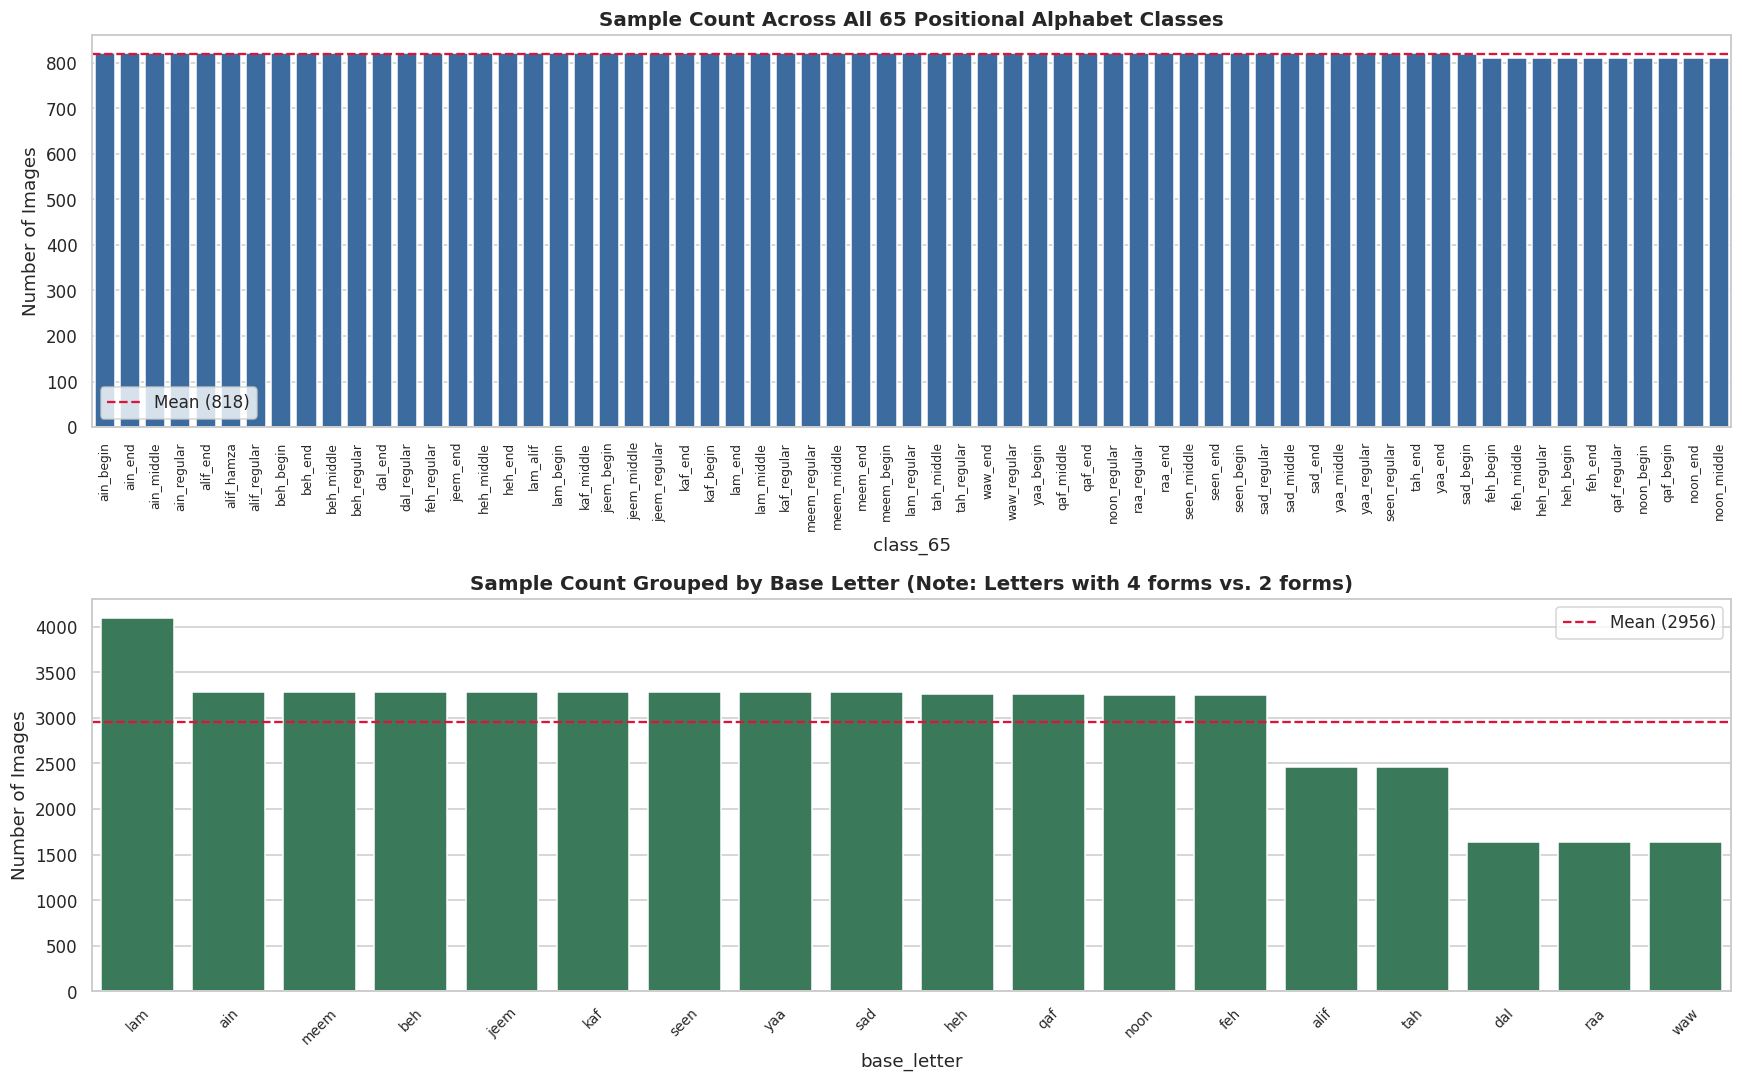

In [3]:
class_counts = df["class_65"].value_counts().sort_values(ascending=False)
base_counts = df["base_letter"].value_counts().sort_values(ascending=False)

print("65-Class Summary:")
print(f"  Min samples/class : {class_counts.min()} ({class_counts.idxmin()})")
print(f"  Max samples/class : {class_counts.max()} ({class_counts.idxmax()})")
print(f"  Mean ± Std        : {class_counts.mean():.1f} ± {class_counts.std():.1f}")
print(f"  Imbalance Ratio   : {class_counts.max() / class_counts.min():.2f}x")

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Plot 1: All 65 classes
sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], color="#2b6cb0")
axes[0].axhline(class_counts.mean(), color="crimson", linestyle="--", label=f"Mean ({class_counts.mean():.0f})")
axes[0].set_title("Sample Count Across All 65 Positional Alphabet Classes", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Number of Images")
axes[0].tick_params(axis="x", rotation=90, labelsize=8)
axes[0].legend()

# Plot 2: Grouped by base Arabic letter
sns.barplot(x=base_counts.index, y=base_counts.values, ax=axes[1], color="#2f855a")
axes[1].axhline(base_counts.mean(), color="crimson", linestyle="--", label=f"Mean ({base_counts.mean():.0f})")
axes[1].set_title("Sample Count Grouped by Base Letter (Note: Letters with 4 forms vs. 2 forms)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Number of Images")
axes[1].tick_params(axis="x", rotation=45, labelsize=9)
axes[1].legend()

plt.tight_layout()
plt.show()

## ***Distribution & Data Leakage Analysis***

Total unique writers       : 82
Min images by one writer   : 600 (user: user045)
Max images by one writer   : 650 (user: user014)
Median images per writer   : 650
Writers covering all 65 cls: 80 / 82


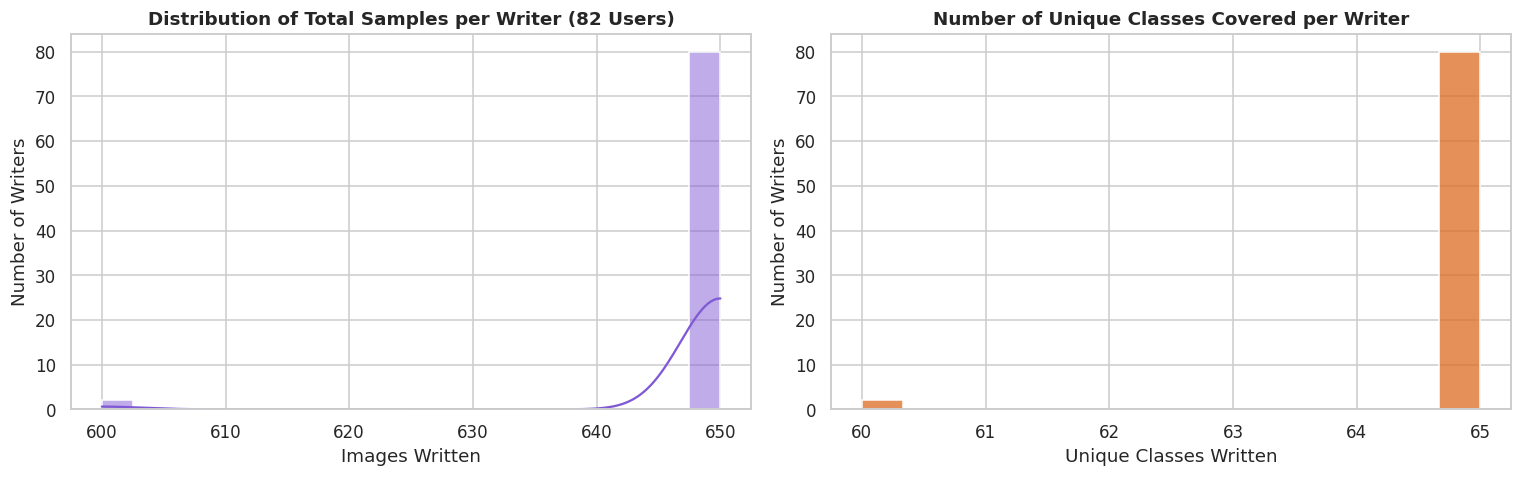

In [4]:
writer_counts = df["user_id"].value_counts().sort_values(ascending=False)
writer_class_coverage = df.groupby("user_id")["class_65"].nunique()

print(f"Total unique writers       : {len(writer_counts)}")
print(f"Min images by one writer   : {writer_counts.min()} (user: {writer_counts.idxmin()})")
print(f"Max images by one writer   : {writer_counts.max()} (user: {writer_counts.idxmax()})")
print(f"Median images per writer   : {writer_counts.median():.0f}")
print(f"Writers covering all 65 cls: {(writer_class_coverage == df['class_65'].nunique()).sum()} / {len(writer_counts)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(writer_counts.values, bins=20, kde=True, ax=axes[0], color="#805ad5")
axes[0].set_title("Distribution of Total Samples per Writer (82 Users)", fontweight="bold")
axes[0].set_xlabel("Images Written")
axes[0].set_ylabel("Number of Writers")

sns.histplot(writer_class_coverage.values, bins=15, ax=axes[1], color="#dd6b20")
axes[1].set_title("Number of Unique Classes Covered per Writer", fontweight="bold")
axes[1].set_xlabel("Unique Classes Written")
axes[1].set_ylabel("Number of Writers")

plt.tight_layout()
plt.show()

## ***Image Dimensions Analysis***

          width   height  aspect_ratio
count  53199.00  53199.0      53199.00
mean     243.72    128.0          1.90
std       76.94      0.0          0.60
min       48.00    128.0          0.38
1%        90.00    128.0          0.70
5%       128.00    128.0          1.00
50%      243.00    128.0          1.90
95%      380.00    128.0          2.97
99%      473.00    128.0          3.70
max      720.00    128.0          5.62


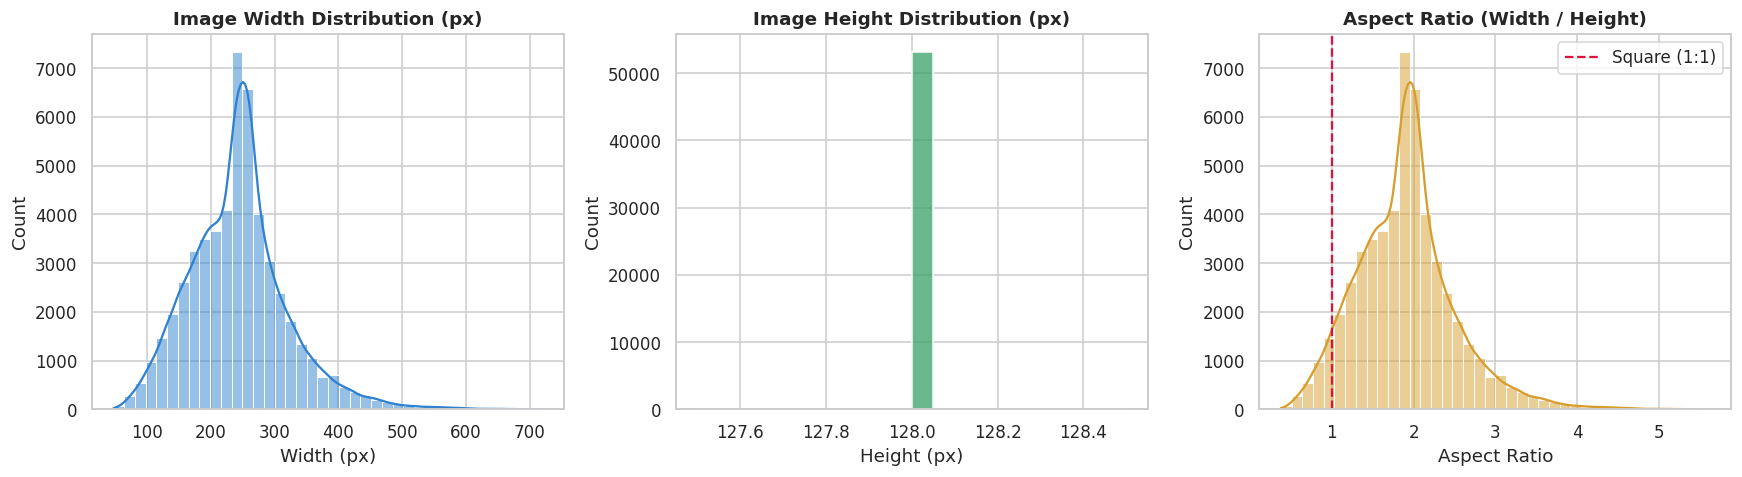


5 Narrowest classes (median W/H):
 class_65
lam_alif       1.50
alif_hamza     1.51
yaa_regular    1.51
kaf_begin      1.61
meem_end       1.61
Name: aspect_ratio, dtype: float64

5 Widest classes (median W/H):
 class_65
kaf_end        2.09
feh_end        2.09
seen_end       2.09
meem_middle    2.11
sad_middle     2.12
Name: aspect_ratio, dtype: float64


In [5]:
print(df[["width", "height", "aspect_ratio"]].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df["width"], bins=40, kde=True, ax=axes[0], color="#3182ce")
axes[0].set_title("Image Width Distribution (px)", fontweight="bold")
axes[0].set_xlabel("Width (px)")

sns.histplot(df["height"], bins=20, ax=axes[1], color="#38a169")
axes[1].set_title("Image Height Distribution (px)", fontweight="bold")
axes[1].set_xlabel("Height (px)")

sns.histplot(df["aspect_ratio"], bins=40, kde=True, ax=axes[2], color="#d69e2e")
axes[2].axvline(1.0, color="crimson", linestyle="--", label="Square (1:1)")
axes[2].set_title("Aspect Ratio (Width / Height)", fontweight="bold")
axes[2].set_xlabel("Aspect Ratio")
axes[2].legend()

plt.tight_layout()
plt.show()

# Show which classes are widest vs. narrowest
ar_by_class = df.groupby("class_65")["aspect_ratio"].median().sort_values()
print("\n5 Narrowest classes (median W/H):\n", ar_by_class.head(5).round(2))
print("\n5 Widest classes (median W/H):\n", ar_by_class.tail(5).round(2))

## ***Pixel intensity and Outliers***

         mean_px     std_px  dark_ratio
count  53199.000  53199.000   53199.000
mean     248.767     26.138       0.041
std        4.199      8.855       0.027
min      217.254      0.000       0.000
0.5%     232.702      8.786       0.005
1%       234.672      9.944       0.006
50%      249.890     24.921       0.034
99%      254.043     50.447       0.129
99.5%    254.212     52.897       0.140
max      255.000     67.655       0.233


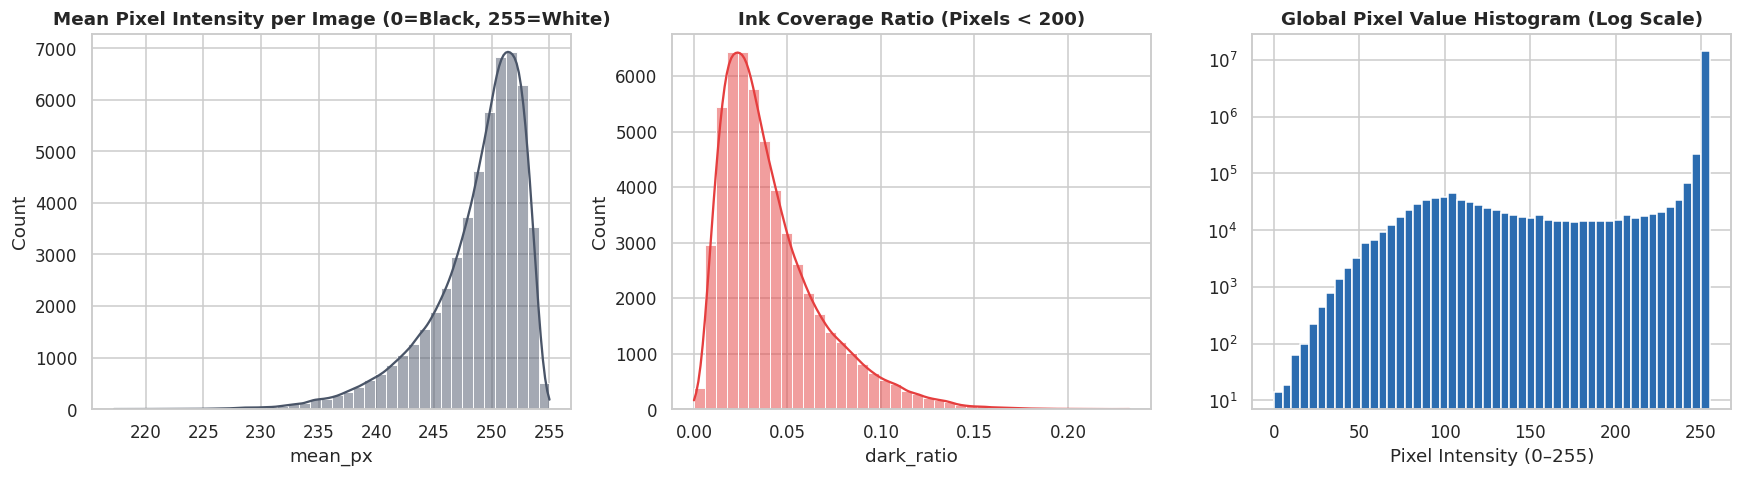

Potential near-blank images (ink < 1%) : 2183
Potential overly dark images (ink > 70%): 0


In [6]:
print(df[["mean_px", "std_px", "dark_ratio"]].describe(percentiles=[0.005, 0.01, 0.5, 0.99, 0.995]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df["mean_px"], bins=40, kde=True, ax=axes[0], color="#4a5568")
axes[0].set_title("Mean Pixel Intensity per Image (0=Black, 255=White)", fontweight="bold")

sns.histplot(df["dark_ratio"], bins=40, kde=True, ax=axes[1], color="#e53e3e")
axes[1].set_title("Ink Coverage Ratio (Pixels < 200)", fontweight="bold")

# Sample 2,000 random images to build a global pixel histogram
sample_paths = df["abs_path"].sample(min(2000, len(df)), random_state=SEED)
sample_pixels = np.concatenate([
    np.asarray(Image.open(p).convert("L")).ravel()[::4] for p in sample_paths
])
axes[2].hist(sample_pixels, bins=50, color="#2b6cb0", log=True)
axes[2].set_title("Global Pixel Value Histogram (Log Scale)", fontweight="bold")
axes[2].set_xlabel("Pixel Intensity (0–255)")

plt.tight_layout()
plt.show()

# Flag potential blank / near-blank or overly dark outliers
faint_outliers = df[df["dark_ratio"] < 0.01]
dark_outliers = df[df["dark_ratio"] > 0.70]
print(f"Potential near-blank images (ink < 1%) : {len(faint_outliers)}")
print(f"Potential overly dark images (ink > 70%): {len(dark_outliers)}")

## ***Visual Samples***

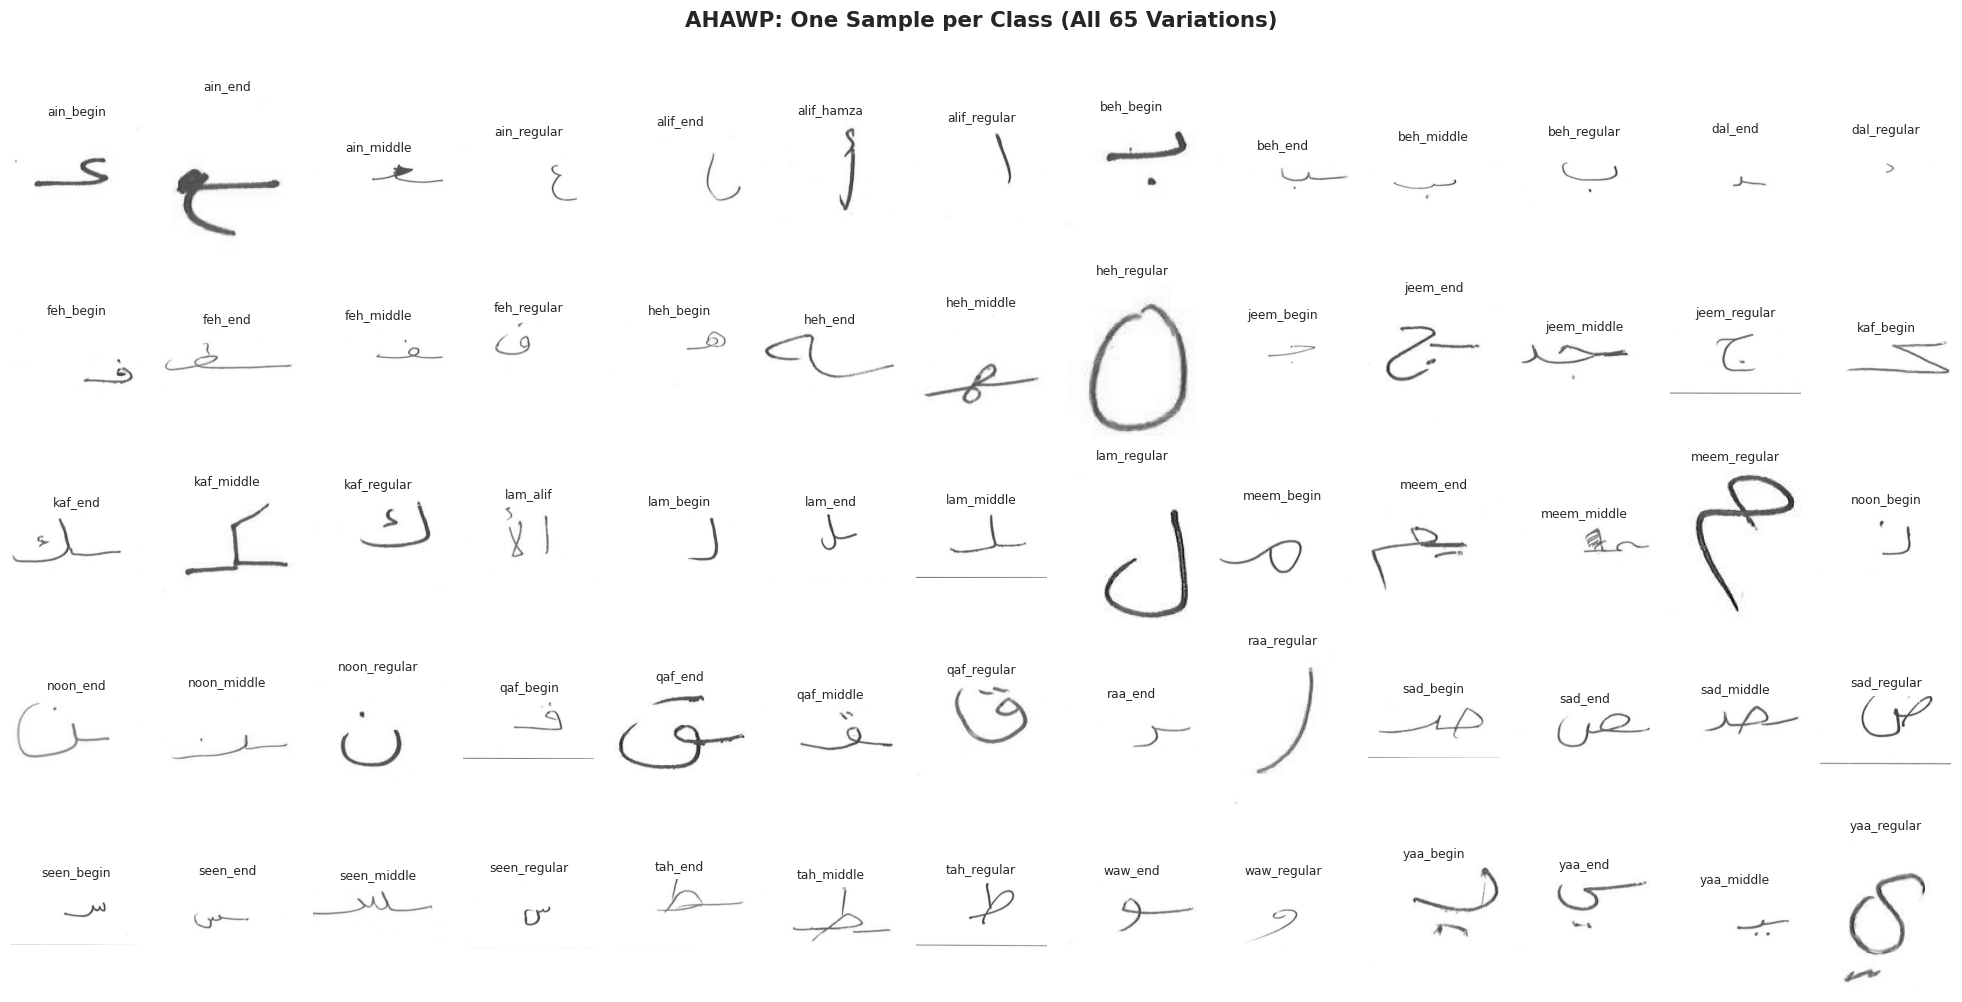

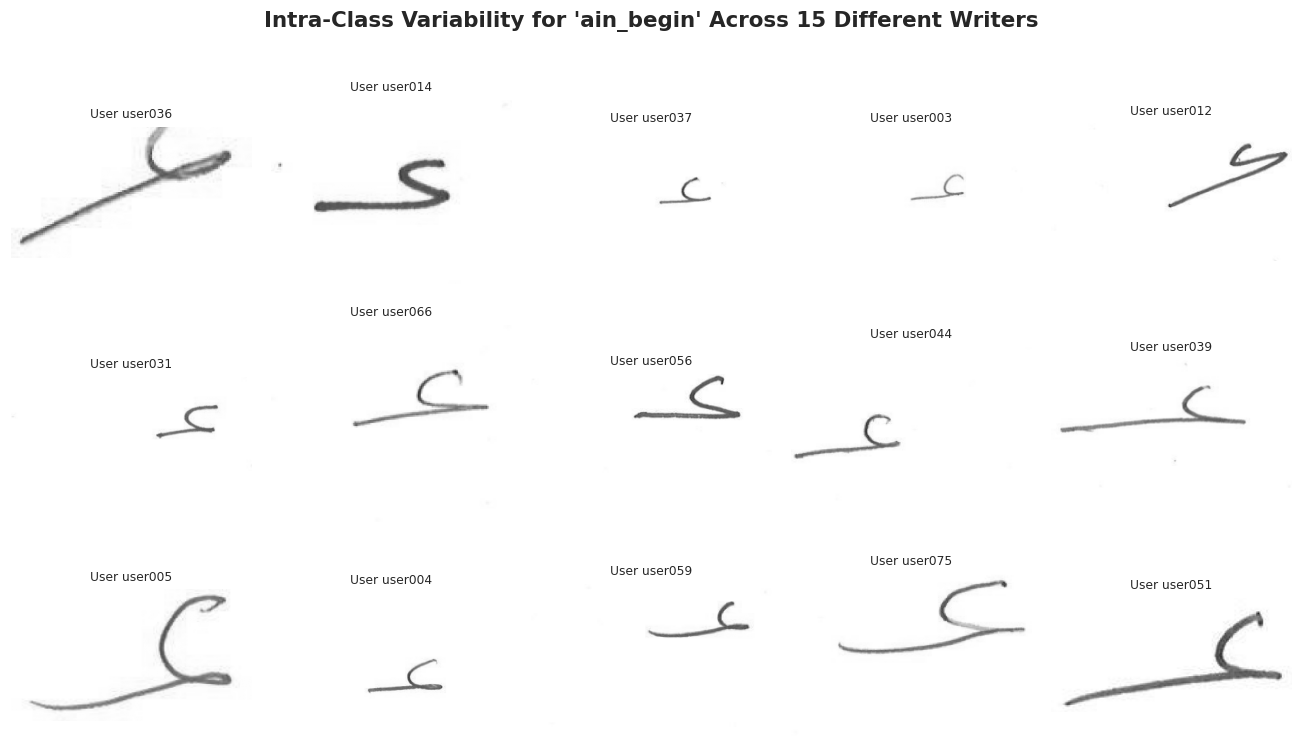

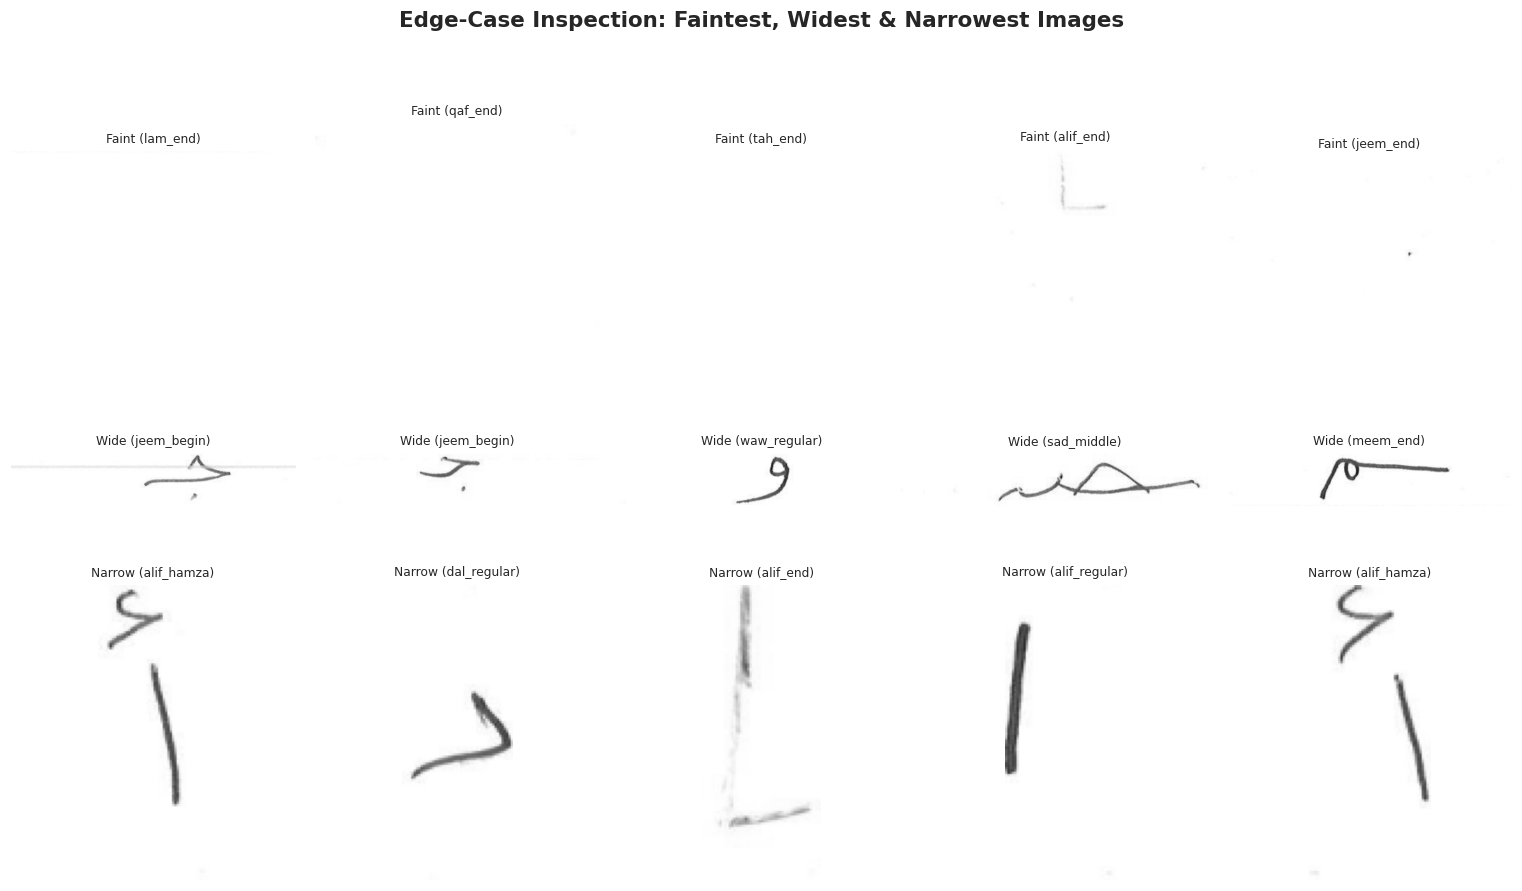

In [7]:
def plot_image_grid(sub_df, title, cols=10, figsize=(16, 10), label_col="class_65"):
    n = len(sub_df)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = np.array(axes).reshape(-1)

    for ax, (_, row) in zip(axes, sub_df.iterrows()):
        img = Image.open(row["abs_path"]).convert("L")
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(str(row[label_col]), fontsize=8)
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    fig.suptitle(title, fontsize=14, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

# 1. One representative sample from each of the 65 classes
one_per_class = df.groupby("class_65", as_index=False).first().sort_values("class_65")
plot_image_grid(one_per_class, "AHAWP: One Sample per Class (All 65 Variations)", cols=13, figsize=(18, 9))

# 2. Intra-class variability: pick 1 class and show 15 different writers
sample_cls = df["class_65"].value_counts().index[0]
variability_df = (
    df[df["class_65"] == sample_cls]
    .drop_duplicates(subset=["user_id"])
    .sample(min(15, df["user_id"].nunique()), random_state=SEED)
)
variability_df = variability_df.assign(caption=lambda d: "User " + d["user_id"])
plot_image_grid(
    variability_df,
    f"Intra-Class Variability for '{sample_cls}' Across 15 Different Writers",
    cols=5, figsize=(12, 7), label_col="caption"
)

# 3. Edge-case audit: 5 faintest, 5 widest, 5 narrowest images
edge_cases = pd.concat([
    df.nsmallest(5, "dark_ratio").assign(tag=lambda d: "Faint (" + d["class_65"] + ")"),
    df.nlargest(5, "aspect_ratio").assign(tag=lambda d: "Wide (" + d["class_65"] + ")"),
    df.nsmallest(5, "aspect_ratio").assign(tag=lambda d: "Narrow (" + d["class_65"] + ")"),
])
plot_image_grid(edge_cases, "Edge-Case Inspection: Faintest, Widest & Narrowest Images", cols=5, figsize=(14, 8), label_col="tag")

## ***Splits***

In [8]:
from sklearn.model_selection import GroupShuffleSplit

# Step 1: Split 15% of writers into TEST (held out until final evaluation!)
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trainval_idx, test_idx = next(gss_test.split(df, df["class_65"], groups=df["user_id"]))

df_trainval = df.iloc[trainval_idx].copy()
df_test = df.iloc[test_idx].copy()

# Step 2: Split ~15% of total (15/85 ≈ 17.65% of trainval) into VALIDATION
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SEED)
train_idx, val_idx = next(gss_val.split(df_trainval, df_trainval["class_65"], groups=df_trainval["user_id"]))

df["split"] = "train"
df.iloc[df_trainval.iloc[val_idx].index, df.columns.get_loc("split")] = "val"
df.iloc[test_idx, df.columns.get_loc("split")] = "test"

# Sanity checks: zero writer overlap + full class coverage
train_users = set(df[df["split"] == "train"]["user_id"])
val_users = set(df[df["split"] == "val"]["user_id"])
test_users = set(df[df["split"] == "test"]["user_id"])

assert train_users.isdisjoint(val_users), "Leakage between train and val!"
assert train_users.isdisjoint(test_users), "Leakage between train and test!"
assert val_users.isdisjoint(test_users), "Leakage between val and test!"

summary = df.groupby("split").agg(
    images=("rel_path", "count"),
    unique_writers=("user_id", "nunique"),
    unique_classes=("class_65", "nunique"),
)
summary["pct_images"] = (summary["images"] / len(df) * 100).round(2)
print(summary)

# Save lightweight manifest (upload to GitHub splits/ folder AND shared Drive)
OUT_CSV = Path("/content/drive/MyDrive/DL_Project/ahawp_splits.csv")
cols_to_save = ["rel_path", "class_65", "base_letter", "variation", "user_id", "width", "height", "split"]
df[cols_to_save].to_csv(OUT_CSV, index=False)
print(f"\nSaved shared split manifest to: {OUT_CSV}")

       images  unique_writers  unique_classes  pct_images
split                                                    
test     8400              13              65       15.79
train   36349              56              65       68.33
val      8450              13              65       15.88

Saved shared split manifest to: /content/drive/MyDrive/DL_Project/ahawp_splits.csv
